# 07 · Exponential integrate-and-fire (EIF): intrinsic onset and numerical cutoff
## Goal
Study nonlinear spike initiation, equilibria, pulse-triggered excitation, firing rates, the QIF near-onset reduction, and cutoff/refractory effects. This is a separate single-neuron study, with a compact LIF comparison at the end.

**Scope:** one deterministic hybrid neuron, without adaptation, noise, synapses, or biological spike waveform. EIF has a nonlinear active flow plus an imposed reset/hold; it is not AdEx and does not include an independent recovery state.

Figures, tables, spike-event records, and a JSON summary are embedded and saved under `results/eif/` relative to the execution directory. No external files or internet connection are needed.

## Setup
### Physical equation and dimensionless reduction
The standard current-based EIF equation is
$$\tau_m\frac{dV}{dt_{physical}}=-(V-E_L)+\Delta_T e^{(V-V_T)/\Delta_T}+RI.$$
Define $u=(V-V_T)/\Delta_T$, $t=t_{physical}/\tau_m$, and
$$\mu=1+\frac{E_L-V_T+RI}{\Delta_T}.$$
Then
$$\dot u=e^u-1-u+\mu\equiv F(u;\mu).$$
For constant current, the intrinsic saddle-node/rheobase is at $u=0,\mu=0$, corresponding to $RI_{rh}=V_T-E_L-\Delta_T$. This follows from $F=F_u=0$; it is **not** the spike event cutoff. The [standard EIF description](https://neuronaldynamics.epfl.ch/online/Ch5.S2.html) distinguishes these roles.

Default reset $u_r=-5$, numerical cutoff $u_{cut}=5$, and refractory hold $\rho=0.1$. At cutoff emit a spike, reset immediately, and hold at reset. Input during the hold is ignored; the clock persists across input changes. Initial rest is computed from the nonlinear equation, not assumed to equal the leak reference.

All quantities below are dimensionless. Frequency is inverse model time, **not Hz**; no measured voltage/current/time calibration is assigned. Equal numerical μ here and j in LIF are not matched physical currents.

### Numerical choices
- DOP853 integrates active flow; terminal interpolation locates cutoff events. Pulse jumps, resets, and holds are explicit segments.
- A constant continuation of the RHS is used **only beyond the cutoff**, outside the active domain, to keep internal solver stages finite. No exponential clipping occurs below cutoff. Events terminate the reported flow at cutoff; quadrature and tolerance checks test its localization.
- Period quadrature, finite-cutoff bias, and near-fold asymptotics are separate references. The infinite-cutoff period still uses a finite reset of −5; it is not an ideal QIF reinjection from −∞.
- No stochastic inputs or confidence intervals. Code requires NumPy, SciPy, pandas, Matplotlib, IPython, and Jupyter, without installing them.

In [2]:
from pathlib import Path
import json
import platform
import numpy as np
import pandas as pd
import scipy
from scipy.integrate import solve_ivp, quad
from scipy.optimize import brentq
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

plt.rcParams.update({'figure.figsize': (9.3, 4.2), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.18,
                     'figure.dpi': 110, 'savefig.dpi': 160})
pd.set_option('display.precision', 7)
COLORS = {'flow': '#2166AC', 'comparison': '#C56A18', 'neutral': '#444444'}
VERSIONS = {'python': platform.python_version(), 'numpy': np.__version__,
            'scipy': scipy.__version__, 'pandas': pd.__version__,
            'matplotlib': matplotlib.__version__}
print(VERSIONS)
EVENT_LOG = []

def show_and_save(fig, stem):
    fig.savefig(OUTPUT_DIR/f'{stem}.png', bbox_inches='tight')
    plt.show()
    plt.close(fig)

def log_run(label, run):
    for index, time in enumerate(run['spikes']):
        EVENT_LOG.append({'experiment': label, 'spike_index': index+1, 'time': time})

OUTPUT_DIR = Path('results')/'eif'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RESET, CUT, REFRACTORY = -5., 5., 0.1

def active_flow(u, mu):
    return np.expm1(u)-u+mu

def rhs(u, drive, cutoff):
    return active_flow(min(float(u), cutoff), drive)

def event_allowed(drive, cutoff):
    return True

def equilibrium_pair(mu):
    if mu >= 0:
        raise ValueError('Two distinct equilibria require μ < 0.')
    left, right = -5., 5.
    while active_flow(left, mu) < 0:
        left *= 2
    while active_flow(right, mu) < 0:
        right *= 2
    return (brentq(lambda u: active_flow(u, mu), left, 0., xtol=1e-14),
            brentq(lambda u: active_flow(u, mu), 0., right, xtol=1e-14))

def reciprocal_flow(u, mu):
    if u < 30:
        return 1/active_flow(u, mu)
    tail = np.exp(-u)
    return tail/(1+(mu-1-u)*tail)

def flight_quadrature(mu, initial=RESET, cutoff=CUT):
    if mu <= 0:
        raise ValueError('This period helper requires strictly positive μ.')
    if not initial < cutoff:
        raise ValueError('Require initial below cutoff.')
    bounds = [initial, 0., cutoff] if initial < 0 < cutoff else [initial, cutoff]
    return float(sum(quad(lambda u: reciprocal_flow(u, mu), lo, hi,
                          epsabs=1e-10, epsrel=1e-10, limit=500)[0]
                     for lo, hi in zip(bounds[:-1], bounds[1:])))

def exact_period(mu, cutoff=CUT, refractory=REFRACTORY):
    # Reference is numerical quadrature of the displayed scalar ODE.
    return flight_quadrature(mu, cutoff=cutoff)+refractory

{'python': '3.12.2', 'numpy': '2.2.6', 'scipy': '1.18.1', 'pandas': '3.0.6', 'matplotlib': '3.11.2'}


## Steps
### 1. Equilibria and intrinsic onset
$F_{uu}=e^u>0$, so the vector field is strictly convex with its minimum at $u=0$. For μ<0 there are two equilibria: stable $u_s<0$ and unstable $u_u>0$, with eigenvalue $e^{u_*}-1$. The unstable point is an excitation boundary for fixed input, distinct from the numerical cutoff.

At μ=0, the equilibria merge and the local drift is $\dot u\approx u^2/2$: attraction from the left is algebraic and the equilibrium is semistable. For μ>0 the drift is positive everywhere. Starting below the fold, repeated firing then requires global reset/reinjection, not the local saddle-node alone.

The finite-cutoff experiments below keep the cutoff above the unstable equilibrium and the reset below it for the negative drives used. A poorly chosen low cutoff could turn threshold detection into an artificial firing mechanism before intrinsic excitation has occurred.

Baseline stable / unstable equilibria: -1.198290437315664 0.857676673945899


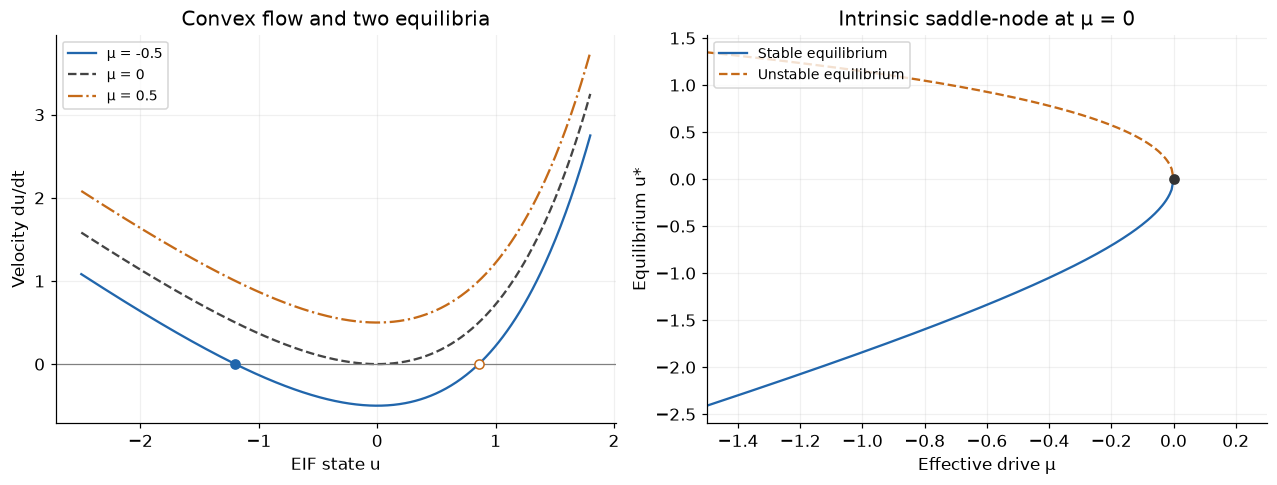

In [4]:
BASE_MU = -0.5
U_STABLE, U_UNSTABLE = equilibrium_pair(BASE_MU)
print('Baseline stable / unstable equilibria:', U_STABLE, U_UNSTABLE)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3), layout='constrained')
ugrid = np.linspace(-2.5, 1.8, 601)
for mu, style, color in [(-0.5, '-', COLORS['flow']), (0., '--', COLORS['neutral']),
                           (0.5, '-.', COLORS['comparison'])]:
    axes[0].plot(ugrid, active_flow(ugrid, mu), style, color=color, label=f'μ = {mu:g}')
axes[0].axhline(0, color='0.5', linewidth=0.8)
axes[0].plot(U_STABLE, 0, 'o', color=COLORS['flow'])
axes[0].plot(U_UNSTABLE, 0, 'o', mfc='white', mec=COLORS['comparison'])
axes[0].set(xlabel='EIF state u', ylabel='Velocity du/dt', title='Convex flow and two equilibria')
axes[0].legend(fontsize=9, loc='upper left')
negative_mu = np.linspace(-1.5, -1e-5, 250)
pairs = np.array([equilibrium_pair(float(mu)) for mu in negative_mu])
axes[1].plot(negative_mu, pairs[:, 0], color=COLORS['flow'], label='Stable equilibrium')
axes[1].plot(negative_mu, pairs[:, 1], '--', color=COLORS['comparison'], label='Unstable equilibrium')
axes[1].plot(0, 0, 'o', color='0.2')
axes[1].set(xlabel='Effective drive μ', ylabel='Equilibrium u*', title='Intrinsic saddle-node at μ = 0', xlim=(-1.5, 0.3))
axes[1].legend(fontsize=9, loc='upper left')
show_and_save(fig, '01_equilibria_and_onset')

### 2. Event/reset integration
The implementation below is self-contained. Active flow, reset, and refractory hold are separate blocks; the hold clock survives an input jump. Sampled states at a spike use the post-reset value.

In [8]:
def simulate(protocol, initial, *, reset=RESET, cutoff=CUT, refractory=REFRACTORY,
             rtol=1e-9, atol=1e-11, method='DOP853', max_step=0.25):
    """Piecewise-constant drives; interpolated events; refractory clock spans segments."""
    if not reset < cutoff or not initial < cutoff or refractory < 0:
        raise ValueError('Require reset and initial below cutoff; refractory >= 0.')
    if not len(protocol) or protocol[0][0] != 0:
        raise ValueError('Protocol must start at t=0.')
    blocks, spikes = [], []
    state, ready_time, previous_stop = float(initial), -np.inf, 0.
    def event(t, y):
        return y[0]-cutoff
    event.direction = 1
    event.terminal = True
    for start, stop, drive in protocol:
        if not np.isclose(start, previous_stop) or not stop > start:
            raise ValueError('Require positive-duration contiguous segments.')
        now = float(start)
        while now < stop-1e-12:
            if now < ready_time:
                hold_end = min(stop, ready_time)
                blocks.append({'kind': 'hold', 'start': now, 'stop': hold_end,
                               'value': reset, 'drive': drive})
                state, now = float(reset), float(hold_end)
                if now >= stop-1e-12:
                    break
            sol = solve_ivp(lambda t, y: [rhs(y[0], drive, cutoff)],
                            (now, stop), [state], method=method,
                            rtol=rtol, atol=atol, max_step=max_step,
                            dense_output=True,
                            events=event if event_allowed(drive, cutoff) else None)
            if not sol.success:
                raise RuntimeError(sol.message)
            blocks.append({'kind': 'flow', 'start': now, 'stop': float(sol.t[-1]),
                           'solution': sol, 'drive': drive})
            if sol.status != 1:
                state, now = float(sol.y[0, -1]), float(stop)
            else:
                time = float(sol.t_events[0][0])
                if time <= now+1e-13:
                    raise RuntimeError('No positive flight time after reset.')
                spikes.append(time)
                state, now, ready_time = float(reset), time, time+refractory
                if len(spikes) > 10000:
                    raise RuntimeError('Spike safety limit exceeded.')
        previous_stop = float(stop)
    return {'blocks': blocks, 'spikes': np.array(spikes), 'final_state': state,
            'reset': reset, 'cutoff': cutoff, 'refractory': refractory,
            'stop': previous_stop}

def sample_run(run, times):
    times = np.asarray(times, dtype=float)
    values = np.full(times.shape, np.nan)
    for block in run['blocks']:
        mask = (times >= block['start']) & (times <= block['stop'])
        if not np.any(mask):
            continue
        values[mask] = block['value'] if block['kind'] == 'hold' else block['solution'].sol(times[mask])[0]
    # Post-reset value defines the right-continuous state at event times.
    for time in run['spikes']:
        values[np.abs(times-time) < 1e-11] = run['reset']
    if not np.isfinite(values).all():
        raise ValueError('Sample times outside simulated coverage.')
    return values

def plot_state(ax, run, *, color, label=None, linestyle='-'):
    """Draw flow/holds separately: no artificial action-potential waveform."""
    labeled = False
    for block in run['blocks']:
        tt = np.linspace(block['start'], block['stop'], 150)
        vv = np.full_like(tt, block['value']) if block['kind'] == 'hold' else block['solution'].sol(tt)[0]
        ax.plot(tt, vv, linestyle, color=color, linewidth=1.2,
                label=label if not labeled else None)
        labeled = True
    for time in run['spikes']:
        ax.plot([time, time], [run['reset'], run['cutoff']], ':', color=color,
                alpha=0.45, linewidth=0.8)

def measured_period(run):
    if len(run['spikes']) < 4:
        raise ValueError('At least four events required for an ISI benchmark.')
    return float(np.diff(run['spikes']).mean())

### 3. Autonomous trajectories and firing-rate curve
Compare μ=−0.5, 0, and 0.5 from reset. The critical run approaches the fold without rotating or repeatedly firing. At positive drive, the reset/cutoff convention closes a repeating hybrid cycle.

For μ>0,
$$T_{cut}(\mu)=\rho+\int_{u_r}^{u_{cut}}\frac{du}{e^u-1-u+\mu},\qquad f_{cut}=1/T_{cut}.$$
This integral is evaluated by numerical quadrature and independently compared with the event-driven ODE. The first spike is the active flight time, without an initial refractory hold. Each subsequent ISI adds the hold.

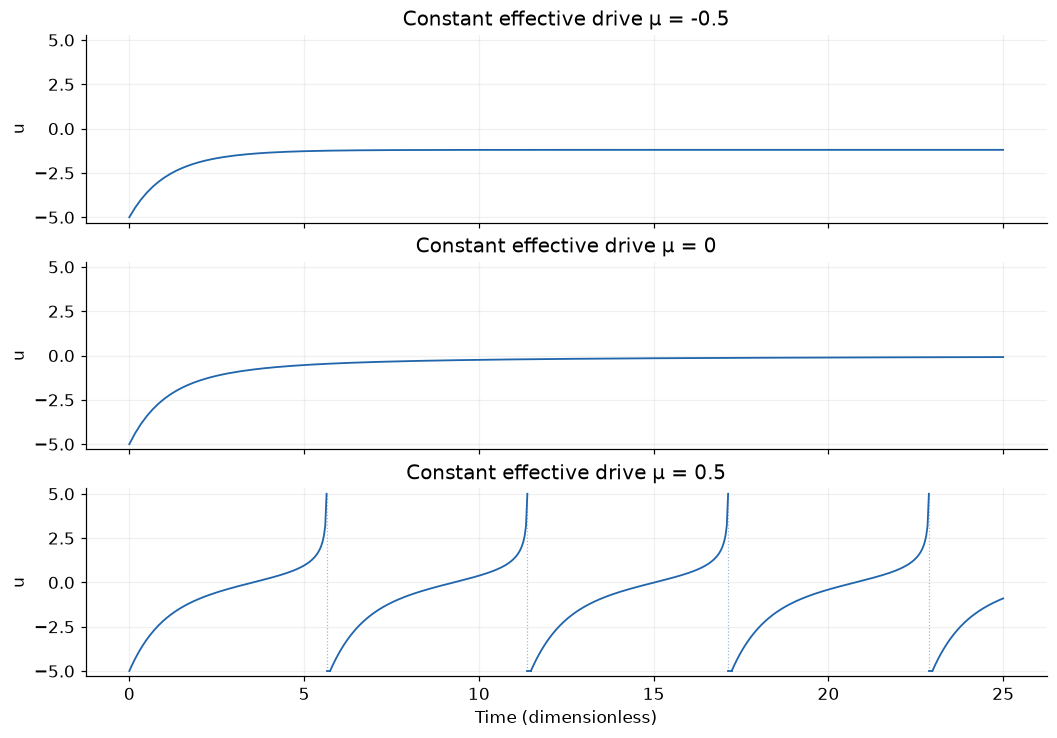

,mu,period_quadrature,period_numeric,frequency_numeric,relative_period_error
0,0.001,140.3036592,140.3036592,0.0071274,2.0403679e-12
1,0.003,80.9064270,80.9064270,0.0123600,2.8297364e-12
2,0.010,44.1884044,44.1884044,0.0226304,4.5776716e-12
3,0.030,25.3626963,25.3626963,0.0394280,6.7321704e-12
4,0.100,13.6775430,13.6775430,0.0731125,2.7504665e-12
5,0.300,7.6301608,7.6301608,0.1310588,1.5962565e-11
6,1.000,3.8290988,3.8290988,0.2611581,3.5178860e-11


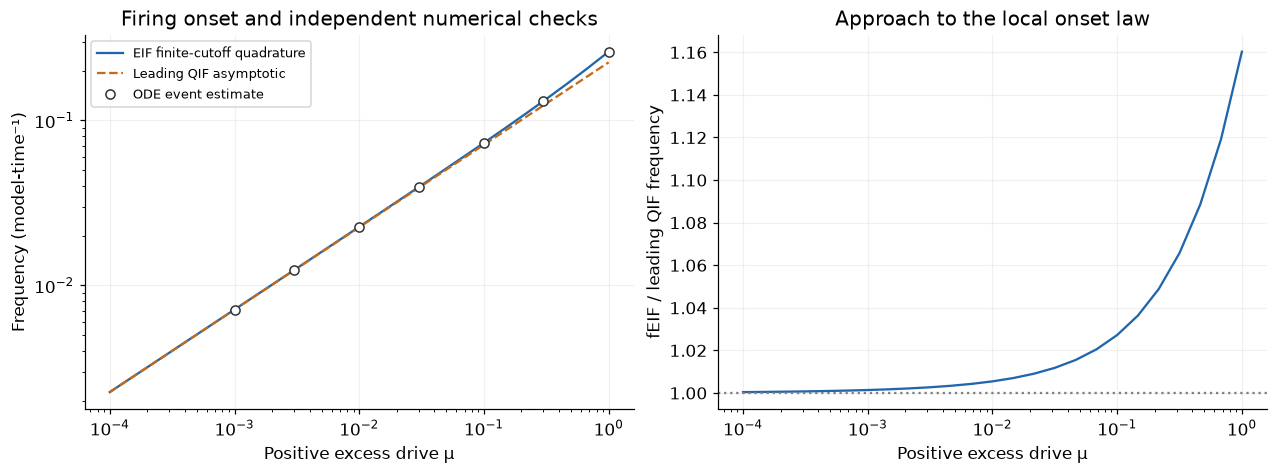

In [10]:
trace_runs = {}
fig, axes = plt.subplots(3, 1, figsize=(9.5, 6.6), sharex=True, layout='constrained')
for ax, mu in zip(axes, [-0.5, 0., 0.5]):
    run = simulate([(0, 25, mu)], RESET)
    trace_runs[mu] = run
    log_run(f'constant_mu_{mu:g}', run)
    plot_state(ax, run, color=COLORS['flow'])
    ax.set(title=f'Constant effective drive μ = {mu:g}', ylabel='u', ylim=(-5.3, 5.3))
axes[-1].set_xlabel('Time (dimensionless)')
show_and_save(fig, '02_constant_drive_traces')

rate_rows = []
for mu in np.geomspace(1e-4, 1., 25):
    T = exact_period(float(mu))
    rate_rows.append({'mu': mu, 'period_quadrature': T, 'frequency_quadrature': 1/T,
                      'qif_leading_frequency': np.sqrt(mu/2)/np.pi})
rate_table = pd.DataFrame(rate_rows)
rate_table['ratio_to_qif_leading'] = rate_table.frequency_quadrature/rate_table.qif_leading_frequency
rate_table.to_csv(OUTPUT_DIR/'quadrature_rate_curve.csv', index=False)
numerical_rows = []
for mu in [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.]:
    F = flight_quadrature(mu)
    T = F+REFRACTORY
    run = simulate([(0, F+3.5*T, mu)], RESET, max_step=0.5)
    log_run(f'rate_mu_{mu:g}', run)
    observed_T = measured_period(run)
    numerical_rows.append({'mu': mu, 'period_quadrature': T, 'period_numeric': observed_T,
                           'frequency_numeric': 1/observed_T,
                           'relative_period_error': abs(observed_T/T-1)})
numerical_table = pd.DataFrame(numerical_rows)
numerical_table.to_csv(OUTPUT_DIR/'ode_rate_checks.csv', index=False)
display(numerical_table)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), layout='constrained')
axes[0].loglog(rate_table.mu, rate_table.frequency_quadrature, color=COLORS['flow'], label='EIF finite-cutoff quadrature')
axes[0].loglog(rate_table.mu, rate_table.qif_leading_frequency, '--', color=COLORS['comparison'], label='Leading QIF asymptotic')
axes[0].loglog(numerical_table.mu, numerical_table.frequency_numeric, 'o', mfc='white', mec='0.2', label='ODE event estimate')
axes[0].set(xlabel='Positive excess drive μ', ylabel='Frequency (model-time⁻¹)', title='Firing onset and independent numerical checks')
axes[0].legend(fontsize=8.5, loc='upper left')
axes[1].semilogx(rate_table.mu, rate_table.ratio_to_qif_leading, color=COLORS['flow'])
axes[1].axhline(1, color='0.5', linestyle=':')
axes[1].set(xlabel='Positive excess drive μ', ylabel='fEIF / leading QIF frequency', title='Approach to the local onset law')
show_and_save(fig, '03_rate_curve_and_qif_limit')

**Local normal-form link:** expand $F(u;\mu)=\mu+u^2/2+O(u^3)$. With $w=u/2$, $\dot w=\mu/2+w^2+O(w^3)$, giving the leading bottleneck period $\pi\sqrt{2/\mu}$ and frequency $\sqrt{\mu/2}/\pi$. This is asymptotic as μ→0+, not a global equivalence between EIF and QIF. Finite reset/cutoff and refractory time contribute corrections; equal model input values across families are not physically matched.

### 4. Finite pulses and delayed excitation
At baseline μ=−0.5 start from the computed stable equilibrium, and add a pulse $A=1.5$, so μ becomes 1 during the pulse. To leave the state exactly at the baseline unstable equilibrium requires
$$D_{crit}=\int_{u_s(-0.5)}^{u_u(-0.5)}\frac{du}{F(u;1)}.$$
Equality is unstable balance, not robust spiking. We compare $0.8D_{crit}$ and $1.2D_{crit}$, both shorter than the pulse-driven flight to cutoff. After the stronger pulse ends, the state remains above the baseline unstable equilibrium and fires later. After reset it returns to rest. This separates the intrinsic excitation boundary from the spike event cutoff.

,duration_over_critical,duration,u_at_pulse_end,pulse_off_time,n_spikes,first_spike_time,final_distance_to_rest
0,0.8,1.4274713,0.4094228,3.4274713,0,NaN,2.9005578e-08
1,1.2,2.1412070,1.6382010,4.1412070,1,4.4561145,4.7572281e-08


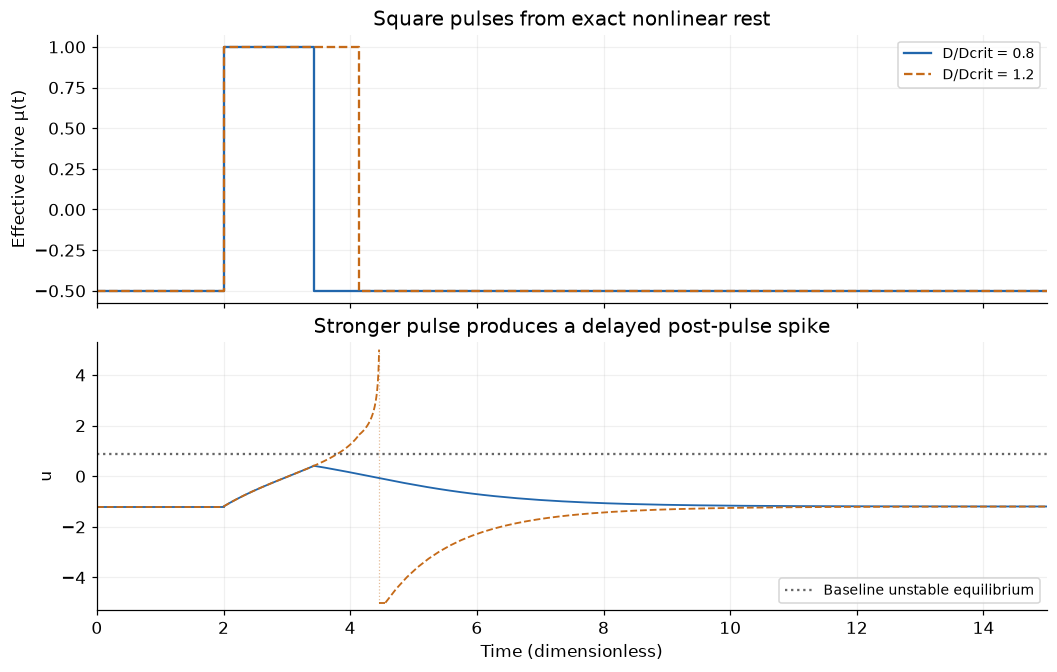

In [12]:
PULSE_A, PULSE_ON = 1.5, 2.
PULSE_MU = BASE_MU+PULSE_A
D_CRIT = quad(lambda u: 1/active_flow(u, PULSE_MU), U_STABLE, U_UNSTABLE,
              epsabs=1e-11, epsrel=1e-11)[0]
pulse_runs, pulse_rows = {}, []
for factor in [0.8, 1.2]:
    duration = factor*D_CRIT
    off = PULSE_ON+duration
    run = simulate([(0, PULSE_ON, BASE_MU), (PULSE_ON, off, PULSE_MU),
                     (off, 30, BASE_MU)], U_STABLE)
    pulse_runs[factor] = run
    log_run(f'pulse_D_over_Dcrit_{factor:g}', run)
    pulse_rows.append({'duration_over_critical': factor, 'duration': duration,
                       'u_at_pulse_end': sample_run(run, [off])[0],
                       'pulse_off_time': off, 'n_spikes': len(run['spikes']),
                       'first_spike_time': float(run['spikes'][0]) if len(run['spikes']) else np.nan,
                       'final_distance_to_rest': abs(run['final_state']-U_STABLE)})
pulse_table = pd.DataFrame(pulse_rows)
pulse_table.to_csv(OUTPUT_DIR/'pulse_responses.csv', index=False)
display(pulse_table)

def pulse_endpoint_margin(duration):
    run = simulate([(0, duration, PULSE_MU)], U_STABLE, rtol=1e-11, atol=1e-13, max_step=0.05)
    if len(run['spikes']):
        raise ValueError('Threshold root bracket must precede the cutoff event.')
    return run['final_state']-U_UNSTABLE

D_CRIT_NUMERIC = brentq(pulse_endpoint_margin, 0.8*D_CRIT, 1.2*D_CRIT, xtol=1e-11, rtol=1e-12)
fig, axes = plt.subplots(2, 1, figsize=(9.5, 6), sharex=True, layout='constrained')
for factor, style, color in [(0.8, '-', COLORS['flow']), (1.2, '--', COLORS['comparison'])]:
    off = PULSE_ON+factor*D_CRIT
    axes[0].step([0, PULSE_ON, off, 30], [BASE_MU, PULSE_MU, BASE_MU, BASE_MU],
                 where='post', linestyle=style, color=color, label=f'D/Dcrit = {factor:g}')
    plot_state(axes[1], pulse_runs[factor], color=color, linestyle=style)
axes[0].set(ylabel='Effective drive μ(t)', title='Square pulses from exact nonlinear rest')
axes[0].legend(fontsize=9, loc='upper right')
axes[1].axhline(U_UNSTABLE, color='0.4', linestyle=':', label='Baseline unstable equilibrium')
axes[1].set(xlabel='Time (dimensionless)', ylabel='u', title='Stronger pulse produces a delayed post-pulse spike', xlim=(0, 15), ylim=(-5.3, 5.3))
axes[1].legend(fontsize=9, loc='lower right')
show_and_save(fig, '04_pulse_excitation')

### 5. Cutoff bias is distinct from integration error
With finite reset fixed at −5, define $T_\infty=\rho+\int_{-5}^{\infty}du/F(u;\mu)$ for μ>0. A finite cutoff omits the positive tail, so $T_{cut}<T_\infty$ and its frequency is biased upward. The asymptotic omitted active time is approximately $e^{-u_{cut}}$ at large cutoff.

At μ=0.5 compare cutoffs 2,3,4,5,6,8,10. Each numerical first-flight time is checked against its **finite-cutoff integral**. Cutoff bias is then measured separately against the infinite-cutoff integral. Making the integrator more accurate cannot remove this modeling convention's bias.

The tail integrand is evaluated using $e^{-u}/[1+(\mu-1-u)e^{-u}]$ at large u to avoid overflow; no voltage truncation is inserted into the infinite-cutoff integral.

,cutoff,period_finite_quad,period_infinite_quad,relative_flight_integration_error,omitted_tail_time,relative_frequency_bias
0,2.0,5.5788095,5.7508384,6.9418915e-12,0.1720288,0.0308361
1,3.0,5.6953889,5.7508384,1.1701751e-12,0.0554495,0.0097359
2,4.0,5.7316327,5.7508384,1.1588508e-12,0.0192056,0.0033508
3,5.0,5.7439606,5.7508384,2.1938007e-13,0.0068777,0.0011974
4,6.0,5.7483379,5.7508384,3.9568349e-13,0.0025005,0.0004350
5,8.0,5.7505024,5.7508384,5.0293103e-13,0.0003360,0.0000584
6,10.0,5.7507930,5.7508384,5.0537352e-13,0.0000454,0.0000079


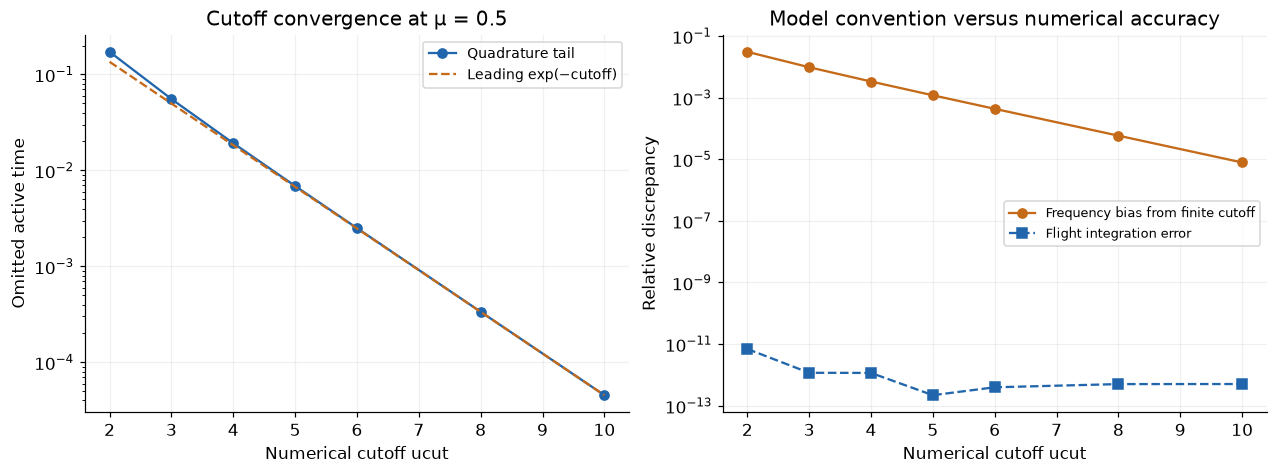

In [14]:
CUTOFF_MU = 0.5
T_INFINITE = exact_period(CUTOFF_MU, cutoff=np.inf)
cutoff_rows = []
for cutoff in [2., 3., 4., 5., 6., 8., 10.]:
    flight = flight_quadrature(CUTOFF_MU, cutoff=cutoff)
    total = flight+REFRACTORY
    run = simulate([(0, 1.5*total, CUTOFF_MU)], RESET, cutoff=cutoff,
                    rtol=1e-10, atol=1e-12, max_step=0.1)
    numeric_flight = float(run['spikes'][0])
    cutoff_rows.append({'cutoff': cutoff, 'period_finite_quad': total,
                        'period_infinite_quad': T_INFINITE,
                        'relative_flight_integration_error': abs(numeric_flight/flight-1),
                        'omitted_tail_time': T_INFINITE-total,
                        'relative_frequency_bias': T_INFINITE/total-1})
cutoff_table = pd.DataFrame(cutoff_rows)
cutoff_table.to_csv(OUTPUT_DIR/'cutoff_bias.csv', index=False)
display(cutoff_table)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), layout='constrained')
axes[0].semilogy(cutoff_table.cutoff, cutoff_table.omitted_tail_time, 'o-', color=COLORS['flow'], label='Quadrature tail')
axes[0].semilogy(cutoff_table.cutoff, np.exp(-cutoff_table.cutoff), '--', color=COLORS['comparison'], label='Leading exp(−cutoff)')
axes[0].set(xlabel='Numerical cutoff ucut', ylabel='Omitted active time', title='Cutoff convergence at μ = 0.5')
axes[0].legend(fontsize=9, loc='upper right')
axes[1].semilogy(cutoff_table.cutoff, cutoff_table.relative_frequency_bias, 'o-', color=COLORS['comparison'], label='Frequency bias from finite cutoff')
axes[1].semilogy(cutoff_table.cutoff, cutoff_table.relative_flight_integration_error, 's--', color=COLORS['flow'], label='Flight integration error')
axes[1].set(xlabel='Numerical cutoff ucut', ylabel='Relative discrepancy', title='Model convention versus numerical accuracy')
axes[1].legend(fontsize=8.5, loc='center right')
show_and_save(fig, '05_cutoff_bias')

### 6. Tolerance convergence and refractory hold across an input jump
At μ=0.5, compare RK45 periods and spike times with quadrature as tolerances tighten. Event-time references include each imposed hold. The test with μ changing from 1 to 5 halfway through the first hold checks that the new drive cannot prematurely release the clamp.

A positive baseline frequency does not require a separate adaptation state; basic EIF cannot create adaptation-dependent burst modulation by itself. Changing a reset/hold changes the hybrid model.

,rtol,relative_period_error,max_spike_time_error
0,1.0000000e-03,1.8675841e-05,5.3636648e-04
1,1.0000000e-05,3.5821700e-06,1.0287922e-04
2,1.0000000e-07,3.8806975e-08,1.1145287e-06
3,1.0000000e-09,1.9308000e-10,5.5451146e-09
4,1.0000000e-11,3.0926373e-12,8.8988372e-11


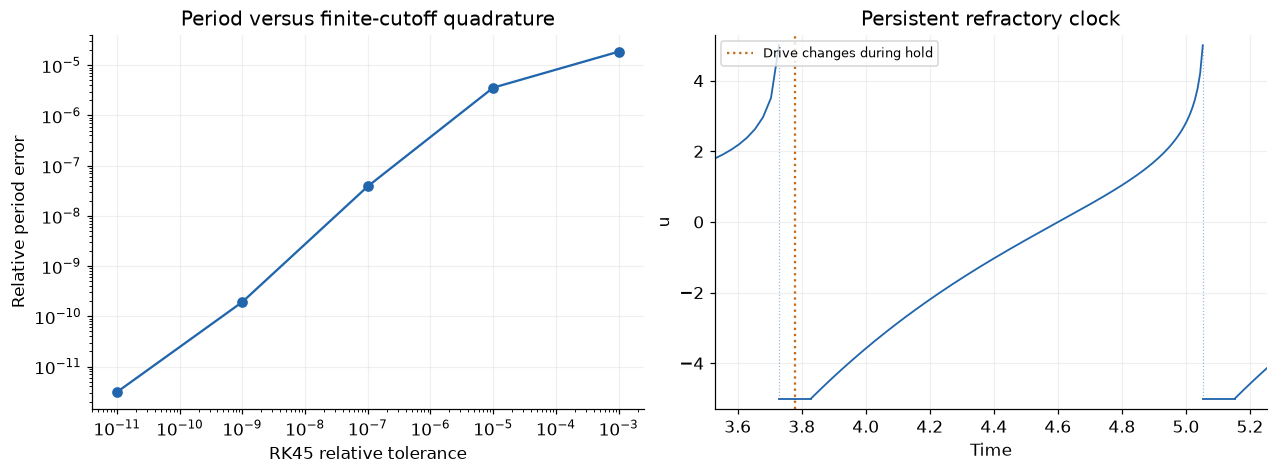

In [16]:
MU_REF = 0.5
F_REF, T_REF = flight_quadrature(MU_REF), exact_period(MU_REF)
convergence_rows = []
for tolerance in [1e-3, 1e-5, 1e-7, 1e-9, 1e-11]:
    run = simulate([(0, F_REF+4.5*T_REF, MU_REF)], RESET, method='RK45',
                    rtol=tolerance, atol=tolerance/100, max_step=0.5)
    expected = F_REF+np.arange(len(run['spikes']))*T_REF
    convergence_rows.append({'rtol': tolerance, 'relative_period_error': abs(measured_period(run)/T_REF-1),
                             'max_spike_time_error': float(np.max(abs(run['spikes']-expected)))})
convergence_table = pd.DataFrame(convergence_rows)
convergence_table.to_csv(OUTPUT_DIR/'solver_convergence.csv', index=False)
display(convergence_table)
first = flight_quadrature(1.)
boundary = first+REFRACTORY/2
expected_second = first+REFRACTORY+flight_quadrature(5.)
guard_run = simulate([(0, boundary, 1.), (boundary, expected_second+1, 5.)], RESET,
                      rtol=1e-10, atol=1e-12, max_step=0.1)
guard_error = abs(guard_run['spikes'][1]-expected_second)
hold_error = abs(sample_run(guard_run, [first+0.075])[0]-RESET)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), layout='constrained')
axes[0].loglog(convergence_table.rtol, convergence_table.relative_period_error, 'o-', color=COLORS['flow'])
axes[0].set(xlabel='RK45 relative tolerance', ylabel='Relative period error', title='Period versus finite-cutoff quadrature')
plot_state(axes[1], guard_run, color=COLORS['flow'])
axes[1].axvline(boundary, color=COLORS['comparison'], linestyle=':', label='Drive changes during hold')
axes[1].set(xlabel='Time', ylabel='u', title='Persistent refractory clock', xlim=(first-0.2, expected_second+0.2), ylim=(-5.3, 5.3))
axes[1].legend(fontsize=8.5, loc='upper left')
show_and_save(fig, '06_convergence_and_refractory_guard')

## Checks
Exact algebra checks equilibria and the saddle-node minimum. Quadrature checks active flight and pulse thresholds; tolerance refinement checks event localization, including the numerical extension beyond the absorbing cutoff. The near-QIF formula is tested as an approximation, with its discrepancy reported separately from solver errors.

In [18]:
equilibrium_residual = max(abs(active_flow(U_STABLE, BASE_MU)), abs(active_flow(U_UNSTABLE, BASE_MU)))
cut5 = cutoff_table[cutoff_table.cutoff == 5.].iloc[0]
checks = [
    ('Baseline equilibrium residual', equilibrium_residual, 1e-11),
    ('Maximum ODE/quadrature relative period error', numerical_table.relative_period_error.max(), 1e-7),
    ('Pulse threshold: ODE root versus quadrature', abs(D_CRIT_NUMERIC/D_CRIT-1), 1e-8),
    ('Maximum finite-cutoff flight integration error', cutoff_table.relative_flight_integration_error.max(), 1e-7),
    ('Tight RK45 relative period error', convergence_table.relative_period_error.iloc[-1], 1e-8),
    ('Tight RK45 maximum spike-time error', convergence_table.max_spike_time_error.iloc[-1], 1e-6),
    ('Hold across input-boundary: next spike error', guard_error, 1e-7),
    ('Held state exactly at reset', hold_error, 1e-12),
    ('Pulse return-to-rest endpoint distance', pulse_table.final_distance_to_rest.max(), 1e-6)]
check_table = pd.DataFrame(checks, columns=['check', 'observed_error', 'limit'])
check_table['passed'] = check_table.observed_error < check_table.limit
assert check_table.passed.all(), check_table.loc[~check_table.passed]
assert np.expm1(U_STABLE) < 0 < np.expm1(U_UNSTABLE)
assert RESET < U_STABLE < 0 < U_UNSTABLE < min(cutoff_table.cutoff)
assert len(trace_runs[-0.5]['spikes']) == len(trace_runs[0.]['spikes']) == 0
assert pulse_table.n_spikes.tolist() == [0, 1]
assert pulse_table.u_at_pulse_end.iloc[0] < U_UNSTABLE < pulse_table.u_at_pulse_end.iloc[1]
assert pulse_table.first_spike_time.iloc[1] > pulse_table.pulse_off_time.iloc[1]
assert 1.2*D_CRIT < flight_quadrature(PULSE_MU, initial=U_STABLE)
assert np.all(cutoff_table.relative_frequency_bias > 0)
assert np.all(np.diff(cutoff_table.omitted_tail_time) < 0)
assert convergence_table.relative_period_error.iloc[-1] < convergence_table.relative_period_error.iloc[0]
assert abs(rate_table.ratio_to_qif_leading.iloc[0]-1) < 0.05  # approximation check, not numerical error
assert np.all(np.diff(guard_run['spikes']) >= REFRACTORY-1e-10)
check_table.to_csv(OUTPUT_DIR/'validation_checks.csv', index=False)
pd.DataFrame(EVENT_LOG).to_csv(OUTPUT_DIR/'spike_events.csv', index=False)
display(check_table)
print('All numerical criteria, pulse/reset assertions, and local-asymptotic check passed.')

,check,observed_error,limit,passed
0,Baseline equilibrium residual,2.2204460e-16,1.0000000e-11,True
1,Maximum ODE/quadrature relative period error,3.5178860e-11,1.0000000e-07,True
2,Pulse threshold: ODE root versus quadrature,6.6613381e-16,1.0000000e-08,True
3,Maximum finite-cutoff flight integration error,6.9418915e-12,1.0000000e-07,True
4,Tight RK45 relative period error,3.0926373e-12,1.0000000e-08,True
5,Tight RK45 maximum spike-time error,8.8988372e-11,1.0000000e-06,True
6,Hold across input-boundary: next spike error,2.9753977e-12,1.0000000e-07,True
7,Held state exactly at reset,0.0000000e+00,1.0000000e-12,True
8,Pulse return-to-rest endpoint distance,4.7572281e-08,1.0000000e-06,True


All numerical criteria, pulse/reset assertions, and local-asymptotic check passed.


## Takeaways
Values below are computed from the executed experiments. Intrinsic onset, event convention, and numerical error remain distinct.

In [20]:
summary = {'versions': VERSIONS, 'units': 'dimensionless', 'reset': RESET, 'cutoff': CUT,
           'refractory': REFRACTORY, 'intrinsic_rheobase_mu': 0.,
           'baseline_mu': BASE_MU, 'stable_equilibrium': U_STABLE, 'unstable_equilibrium': U_UNSTABLE,
           'benchmark_mu': MU_REF, 'benchmark_period_quadrature': T_REF,
           'pulse_amplitude': PULSE_A, 'pulse_critical_duration_quad': D_CRIT,
           'pulse_critical_duration_ode': D_CRIT_NUMERIC,
           'pulse_spike_counts': pulse_table.n_spikes.tolist(),
           'max_relative_period_error': float(numerical_table.relative_period_error.max()),
           'cutoff5_relative_frequency_bias_at_mu0p5': float(cut5.relative_frequency_bias),
           'qif_frequency_ratio_at_mu1e_minus4': float(rate_table.ratio_to_qif_leading.iloc[0]),
           'accuracy_checks_passed': int(check_table.passed.sum())}
(OUTPUT_DIR/'summary.json').write_text(json.dumps(summary, indent=2)+'\n')
display(Markdown(f"""
- **Intrinsic onset:** saddle-node at **μ=0, u=0**; numerical spike cutoff is separately **u=5**.
- **Baseline μ=−0.5:** stable rest **u={U_STABLE:.6f}** and unstable excitation boundary **u={U_UNSTABLE:.6f}**.
- **Benchmark μ=0.5:** finite-cutoff/hold period **{T_REF:.9f}**, frequency **{1/T_REF:.9f}** per model-time unit.
- **Pulse excitation:** critical duration **{D_CRIT:.9f}** for amplitude **1.5** from baseline rest. The **1.2×** pulse fires after the pulse ends; the **0.8×** pulse returns without a spike.
- **Cutoff convention:** cutoff **5** raises the μ=0.5 frequency by **{100*cut5.relative_frequency_bias:.5f}%** relative to the same finite reset with infinite cutoff.
- **QIF connection:** at **μ=10⁻⁴**, EIF frequency / leading QIF frequency = **{rate_table.ratio_to_qif_leading.iloc[0]:.6f}**; this is an asymptotic comparison.
- **Accuracy:** maximum ODE/quadrature relative period difference **{numerical_table.relative_period_error.max():.2e}**; all **{len(check_table)}** numerical criteria and additional assertions passed.
"""))


- **Intrinsic onset:** saddle-node at **μ=0, u=0**; numerical spike cutoff is separately **u=5**.
- **Baseline μ=−0.5:** stable rest **u=-1.198290** and unstable excitation boundary **u=0.857677**.
- **Benchmark μ=0.5:** finite-cutoff/hold period **5.743960637**, frequency **0.174095901** per model-time unit.
- **Pulse excitation:** critical duration **1.784339139** for amplitude **1.5** from baseline rest. The **1.2×** pulse fires after the pulse ends; the **0.8×** pulse returns without a spike.
- **Cutoff convention:** cutoff **5** raises the μ=0.5 frequency by **0.11974%** relative to the same finite reset with infinite cutoff.
- **QIF connection:** at **μ=10⁻⁴**, EIF frequency / leading QIF frequency = **1.000398**; this is an asymptotic comparison.
- **Accuracy:** maximum ODE/quadrature relative period difference **3.52e-11**; all **9** numerical criteria and additional assertions passed.


## LIF / EIF comparison and next steps
| Feature | LIF notebook 06 | EIF notebook 07 |
|---|---|---|
| Active dynamics | Linear leak | Leak plus exponential initiation |
| Onset | Stable linear equilibrium reaches imposed threshold boundary | Intrinsic saddle-node in active flow, plus global reset |
| Near-onset period | Logarithmic divergence | Leading μ⁻¹ᐟ² bottleneck divergence |
| Threshold versus cutoff | Imposed threshold defines firing | Unstable equilibrium / fold and numerical cutoff have different roles |
| After a finite pulse at subthreshold baseline | Below-cutoff voltage decays; no delayed autonomous spike in the demonstrated zero-baseline case | Above unstable equilibrium, delayed spike can occur after pulse ends |
| Recovery/adaptation | Imposed reset/hold only | Imposed reset/hold only; no AdEx variable |

These are structural comparisons, not a matched-current prediction or realism ranking. Hybrid models need a simulation interface that supports events, resets, and refractory clocks before mixing them with smooth-flow nodes in networks.

### References and limitations
- Gerstner et al. (2014), *Neuronal Dynamics*, [§5.2: exponential integrate-and-fire](https://neuronaldynamics.epfl.ch/online/Ch5.S2.html), and [§1.3: LIF construction](https://neuronaldynamics.epfl.ch/online/Ch1.S3.html). Accessed 2026-10-27. Derivations and experiments here use the explicitly displayed nondimensionalized equations.
- [SciPy solve_ivp documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html), for event interpolation; package versions appear above.

**Limits:** reset/hold rules are imposed, not a continuous recovery mechanism. The cutoff is not an observed spike amplitude. Quadrature references are numerical evaluations of exact time-of-flight integrals, with no claim of experimentally verified accuracy. The local QIF reduction need not describe far-from-onset trajectories. For subthreshold drive, the reset/cutoff must be placed consistently with the intrinsic equilibria. No fitted physical units, intrinsic bursting, adaptation, stochasticity, or collective behavior is inferred. Project PDFs are not analyzed here.